# First look: same car, different driver

Hamilton vs Russell (Mercedes teammates) on their fastest laps at the 2024 Bahrain GP.
Same car, same race, same day, so the differences in their telemetry are (mostly) the driver.

In [1]:
import logging
import warnings
from pathlib import Path

import fastf1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
logging.getLogger("fastf1").setLevel(logging.ERROR)  # fastf1 info logs are noisy

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE_DIR = PROJECT / "data" / "cache"      # same cache as src/download.py
FIG_DIR = PROJECT / "figures"
FIG_DIR.mkdir(exist_ok=True)

fastf1.Cache.enable_cache(str(CACHE_DIR))
print("cache:", CACHE_DIR)

cache: /Users/elasigin/Documents/Coterm/Fall26/CS230/f1_project/data/cache


## Load the race

In [2]:
session = fastf1.get_session(2024, "Bahrain", "R")
session.load(telemetry=True, weather=True, messages=False)

laps = session.laps   # one row per lap per driver
print(session.event["EventName"], session.event["EventDate"].date())
print(f"{len(laps)} laps, {laps['Driver'].nunique()} drivers")

Bahrain Grand Prix 2024-03-02
1129 laps, 20 drivers


## The laps table

In [3]:
print("laps shape: ", laps.shape)
print("column names: ", laps.columns)
to_display_cols = ["Driver", "Team", "LapNumber", "LapTime", "Compound", "TyreLife", "TrackStatus", "IsAccurate"]
laps_display = laps[to_display_cols].head() # default displays first 5 rows
# check ham / russ are both merc
merc_laps = laps[laps["Driver"].isin(["HAM", "RUS"])]

print(laps_display)
print(merc_laps.groupby("Driver")["Team"].unique())

laps shape:  (1129, 31)
column names:  Index(['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint',
       'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time',
       'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime',
       'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest',
       'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime',
       'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason',
       'FastF1Generated', 'IsAccurate'],
      dtype='object')
  Driver             Team  LapNumber                LapTime Compound  \
0    VER  Red Bull Racing        1.0 0 days 00:01:37.284000     SOFT   
1    VER  Red Bull Racing        2.0 0 days 00:01:36.296000     SOFT   
2    VER  Red Bull Racing        3.0 0 days 00:01:36.753000     SOFT   
3    VER  Red Bull Racing        4.0 0 days 00:01:36.647000     SOFT   
4    VER  Red Bull Racing        5.0 0 days 00:01:37.173000     SOFT   

   TyreLife TrackStatus 

## Fastest lap per driver

In [4]:
ham_lap = laps.pick_drivers("HAM").pick_fastest()
rus_lap = laps.pick_drivers("RUS").pick_fastest()
print("HAM: laptime: ", ham_lap["LapTime"], ", Lap Number: ", ham_lap["LapNumber"], ", Compound: ", ham_lap["Compound"], ", Tyre Life:  ", ham_lap["TyreLife"])
print("RUS: laptime: ", rus_lap["LapTime"], ", Lap Number: ", rus_lap["LapNumber"], ", Compound: ", rus_lap["Compound"], ", Tyre Life:  ", rus_lap["TyreLife"])

HAM: laptime:  0 days 00:01:34.722000 , Lap Number:  39.0 , Compound:  HARD , Tyre Life:   6.0
RUS: laptime:  0 days 00:01:35.065000 , Lap Number:  40.0 , Compound:  HARD , Tyre Life:   9.0


## Telemetry
Different sample counts and lap distances per driver, which is why everything gets resampled below.

In [5]:
ham_tel = ham_lap.get_car_data().add_distance()
rus_tel = rus_lap.get_car_data().add_distance()

print(ham_tel.shape, ham_tel.columns)
print("HAM MAX DIST: ", ham_tel["Distance"].max())
print("RUS MAX DIST: ", rus_tel["Distance"].max())
# sampling interval, median ignores the NaN in row 0 + any odd gaps
for name, tel in [("HAM", ham_tel), ("RUS", rus_tel)]:
    dt = tel["Time"].diff().dt.total_seconds()
    print(f"{name}: {len(tel)} samples, median interval {dt.median():.3f} s "
          f"(~{1 / dt.median():.1f} Hz), min {dt.min():.3f} s, max {dt.max():.3f} s")

(345, 11) Index(['Date', 'RPM', 'Speed', 'nGear', 'Throttle', 'Brake', 'DRS', 'Source',
       'Time', 'SessionTime', 'Distance'],
      dtype='object')
HAM MAX DIST:  5362.406388888891
RUS MAX DIST:  5343.119722222221
HAM: 345 samples, median interval 0.240 s (~4.2 Hz), min 0.159 s, max 1.000 s
RUS: 357 samples, median interval 0.240 s (~4.2 Hz), min 0.159 s, max 0.960 s


## Speed / throttle / brake comparison

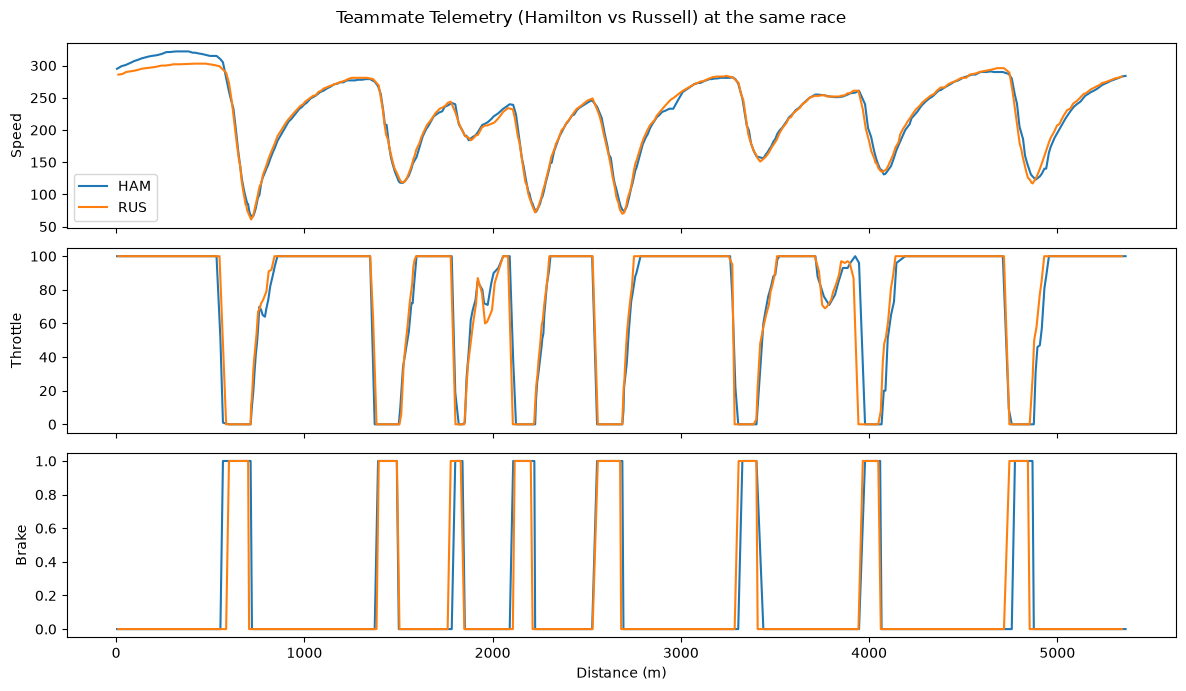

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(ham_tel['Distance'], ham_tel['Speed'], label='HAM')
axes[0].plot(rus_tel['Distance'], rus_tel['Speed'], label='RUS')
axes[0].set_ylabel('Speed')

axes[1].plot(ham_tel['Distance'], ham_tel['Throttle'], label='HAM')
axes[1].plot(rus_tel['Distance'], rus_tel['Throttle'], label='RUS')
axes[1].set_ylabel('Throttle')

# brake is a bool
axes[2].plot(ham_tel['Distance'], ham_tel['Brake'].astype(float), label='HAM')
axes[2].plot(rus_tel['Distance'], rus_tel['Brake'].astype(float), label='RUS')
axes[2].set_ylabel('Brake')
axes[-1].set_xlabel("Distance (m)")
axes[0].legend()

fig.suptitle("Teammate Telemetry (Hamilton vs Russell) at the same race")
fig.tight_layout()
fig.savefig(FIG_DIR / "ham_vs_rus_bahrain2024.pdf", bbox_inches="tight")

**Observations:**
- The two laps are nearly identical: braking points mostly agree within ~20 m (≈ one sample at speed) and minimum corner speeds within ~5 km/h.
- The most consistent difference is corner exit: RUS returns to full throttle earlier at most corners (up to ~50 m earlier at T13).
- Visible differences are confounded by non-driver factors: HAM had DRS on the main straight (315 vs 301 km/h, explaining his earlier T1 braking), tyre age differed (6 vs 9 laps), and distance integration drifts ~19 m over the lap.

## Resample to a fixed length
Every lap -> (5, 512) on a normalized distance grid so they can be batched.

In [7]:
CHANNELS = ["Speed", "Throttle", "Brake", "RPM", "nGear"]

def resample_lap(tel: pd.DataFrame, n_points: int = 512) -> np.ndarray:
    """Interpolate one lap's telemetry onto n_points evenly spaced positions along the lap.
    Returns an array of shape (len(CHANNELS), n_points)."""
    max_dist = tel['Distance'].max()
    dist = tel['Distance'].to_numpy(dtype=float)
    dist /= max_dist
    x_grid = np.linspace(0, 1, n_points)
    rows = []
    for channel in CHANNELS:
        rows.append(np.interp(x_grid, dist, tel[channel].to_numpy(dtype=float))) # dtype=float also handles the brake bool
    return np.stack(rows, axis=0) # one row per channel

In [8]:
ham_arr = resample_lap(ham_tel)
rus_arr = resample_lap(rus_tel)
assert ham_arr.shape == (5, 512), ham_arr.shape
assert rus_arr.shape == (5, 512), rus_arr.shape
assert not np.isnan(ham_arr).any()
assert 0 <= ham_arr[2].min() and ham_arr[2].max() <= 1  # brake in [0, 1]
print("HAM and RUS laps are now the same shape:", ham_arr.shape)

HAM and RUS laps are now the same shape: (5, 512)
